# Wyniki końcowe (final) – H1–H3 i Q1(a), etykiety Gemini, 20 wydarzeń

Ten notebook jest **finalną wersją** analizy: liczby i wykresy z niego są w preprincie (folder `reports/final_gemini/`).
Liczy tak samo jak wcześniejsze notebooki, zmieniło się tylko **skąd bierzemy etykiety i ile jest wydarzeń**:

| | wcześniej | teraz (final) |
|---|---|---|
| wydarzenia | 7 (LLM) / 11 (HerBERT) | **20** |
| `hate_migrant`, `migrant` | LLM przez Ollamę (`labeled/`) | **Gemini 3.5 Flash-Lite** (`llm/`) |
| `hate` (hejt ogólny) | HerBERT (`herbert/`) | **Gemini** (`llm/`); HerBERT jako **sprawdzenie** |
| okno | −7…+14 dni | −7…+14 dni (bez zmian) |
| jednostka | komórka wydarzenie × platforma | bez zmian |

**Mianownik:** wszystkie komentarze komórki w oknie; komentarz, który nie przeszedł filtra tematycznego (nie trafił do Gemini), ma 0 dla każdej etykiety.
**Wersja danych:** każda komórka jest liczona na tej wersji `clean/`, na której puszczono Gemini (md5 z `dvc.lock`, plik z lokalnego cache DVC) – etykiety i komentarze zawsze do siebie pasują.

Ten sam kod jest w `scripts/final_analysis_gemini.py` (do odpalenia z terminala).

## 0. Konfiguracja
Wydarzenia, typy, okno, kolory. `STEPS` mówi, które części liczy ten notebook (Q1(b) jest w `7_hate_analysis/hate_analysis_final.ipynb`).

In [1]:
import gc
import json
import re
import sys
import warnings
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yaml
from scipy import stats
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
OUT = ROOT / "reports" / "final_gemini"
OUT.mkdir(parents=True, exist_ok=True)
STEPS = {'h', 'q1a'}   # which parts this notebook computes

PLATFORMS = ["wykop", "youtube", "bluesky"]
PNAME = {"wykop": "Wykop", "youtube": "YouTube", "bluesky": "Bluesky"}
EVENTS = {  # folder: (English label, type)
    "2022-02-24_Atak_Rosji_Ukraina": ("Russian invasion of Ukraine", "war"),
    "2022-05-08_Zabojstwo_Nowy_Swiat": ("Murder in Warsaw", "disinformation"),
    "2023-09-22_Premiera_Zielona_Granica": ("Film Green Border", "political"),
    "2023-10-15_Referendum_Wybory": ("Election and referendum", "political"),
    "2024-04-10_Pakt_Azyl_PE": ("EU Pact adopted", "political"),
    "2024-05-28_Atak_Zolnierz_Granica": ("Attack on a soldier", "criminal"),
    "2024-06-06_Smierc_Zolnierza": ("Death of the soldier", "criminal"),
    "2024-09-08_Bojka_Srem": ("Brawl in Śrem", "criminal"),
    "2024-10-12_Strategia_Migracyjna": ("Migration strategy", "political"),
    "2024-12-20_Atak_Jarmark_Magdeburg": ("Magdeburg market attack", "criminal"),
    "2025-03-30_Dezinformacja_Wroclaw_Relokacja_Migrantow": ("Wrocław relocation hoax", "disinformation"),
    "2025-06-06_Naloty_ICE_Los_Angeles": ("ICE raids, LA", "political"),
    "2025-07-19_Protesty_Antyimigracyjne_Polska": ("Anti-migration protests", "political"),
    "2025-07-31_Dezinformacja_Swinoujscie_Autokar_Migranci": ("Świnoujście bus hoax", "disinformation"),
    "2025-10-15_Dezinformacja_Krakow": ("Kraków murder", "disinformation"),
    "2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie": ("EU Pact in force", "political"),
    "2026-07-11_Atak_Ukrainskie_Nastolatki_Bielsko_Biala": ("Bielsko-Biała attack", "criminal"),
    "2026-07-30_Ceuta_Masowe_Przekroczenie": ("Ceuta mass crossing", "border crisis"),
    "2026-08-15_Atak_Kamienna_Gora": ("Kamienna Góra attack", "criminal"),
    "2026-09-15_Atak_Jaroslaw": ("Jarosław attack", "criminal"),
}
TYPES = ["criminal", "political", "disinformation", "border crisis", "war"]
EXCLUDE = {("youtube", "2024-06-06_Smierc_Zolnierza")}   # the whole 'before' period is one video
WINDOW, MIN_N = (-7, 14), 30
MEAS = {"hate": "hate", "hate_migrant": "hate_migrant", "migrant": "migrant"}
MNAME = {"hate": "General hate (hate)", "hate_migrant": "Hate toward migrants (hate_migrant)",
         "migrant": "Comments about migration (migrant)"}
PCOL = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TCOL = dict(zip(TYPES, ["#c2410c", "#7c3aed", "#0f766e", "#b45309", "#52514e"]))
INK, INK2, MUTED, HATE_C, NON_C = "#1a2233", "#52514e", "#8a8984", "#b4381f", "#9aa3ad"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 220, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})
R = {}   # results.json
if STEPS and (OUT / "results.json").exists():
    R = json.loads((OUT / "results.json").read_text(encoding="utf-8"))
ORDER = list(EVENTS)
LBL = {ev: v[0] for ev, v in EVENTS.items()}


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def jdump():
    (OUT / "results.json").write_text(json.dumps(R, indent=1, ensure_ascii=False, default=float), encoding="utf-8")

## Dane
Wczytanie komentarzy (`clean/` w wersji użytej przez Gemini) i etykiet (`llm/`, `herbert/`) dla każdej komórki.

In [2]:
# ---------------------------------------------------------------- 0. data -------------------------------------------
LOCK = yaml.safe_load((ROOT / "dvc.lock").read_text(encoding="utf-8"))["stages"]
CACHE = ROOT / ".dvc" / "cache" / "files" / "md5"


def cache_path(md5):
    p = CACHE / md5[:2] / md5[2:]
    return p if p.exists() else None


def llm_clean_file(platform, folder):
    """comments.csv of `clean` in the version the llm@ stage was run on (dvc.lock dep md5 -> local cache)."""
    for name, st in LOCK.items():
        if not name.startswith("llm@"):
            continue
        if not any(o["path"] == f"data/interim/{platform}/{folder}/llm" for o in st.get("outs", [])):
            continue
        dep = [d for d in st["deps"] if d["path"].endswith(f"{platform}/{folder}/clean")]
        if dep and (c := cache_path(dep[0]["md5"])):
            for f in json.loads(c.read_text()):
                if f["relpath"] == "comments.csv" and (p := cache_path(f["md5"])):
                    return p, dep[0]["md5"]
    return ROOT / "data" / "interim" / platform / folder / "clean" / "comments.csv", "workspace"


def as_bool(s):
    return s.astype(str).str.strip().isin(["1", "1.0", "True", "true"])


BASE_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "replies", "text_raw"]


def load_cell(platform, folder):
    d = ROOT / "data" / "interim" / platform / folder
    lf = d / "llm" / "comments.csv"
    if not lf.exists():
        return None, None
    cf, ver = llm_clean_file(platform, folder)
    c = pd.read_csv(cf, encoding="utf-8-sig", usecols=lambda x: x in BASE_COLS,
                    dtype={"comment_id": str, "thread_id": str, "author_id": str, "text_raw": str})
    c = c.drop_duplicates("comment_id")
    n_all_period = len(c)
    c = c[c["relative_day"].between(*WINDOW)].copy()
    lab = pd.read_csv(lf, encoding="utf-8-sig", dtype=str).drop_duplicates("comment_id")
    # one older run of llm_classify.py used shorter column names
    lab = lab.rename(columns={"is_about_migration": "llm_is_about_migration", "hate": "llm_is_hate_general",
                              "hate_migrants": "llm_is_hate_migrants"})
    x = c.merge(lab[["comment_id", "text", "llm_is_about_migration", "llm_is_hate_general", "llm_is_hate_migrants",
                     "source"]], on="comment_id", how="left", indicator=True)
    topic = x.pop("_merge").eq("both")
    x["topic"] = topic
    x["migrant"] = topic & as_bool(x["llm_is_about_migration"])
    x["hate"] = topic & as_bool(x["llm_is_hate_general"])
    x["hate_migrant"] = topic & as_bool(x["llm_is_hate_migrants"])
    x["slur"] = topic & x["source"].eq("slur")
    # robustness: general hate from HerBERT-HS + slur dictionary (its own topic filter; other comments = 0)
    hf = d / "herbert" / "comments.csv"
    has_hb = hf.exists()
    if has_hb:
        hb = pd.read_csv(hf, encoding="utf-8-sig", usecols=["comment_id", "in_topic", "hate_final"], dtype=str)
        hb = hb[as_bool(hb["in_topic"]) & as_bool(hb["hate_final"])]
        x["hate_herbert"] = x["comment_id"].isin(set(hb["comment_id"]))
    else:
        x["hate_herbert"] = False
    x["po"] = (x["relative_day"] >= 0).astype(np.int8)
    x["platform"], x["event"] = platform, folder
    x["cell"] = f"{platform}:{folder}"
    x["thread"] = x["cell"] + ":" + x["thread_id"].astype(str)
    x["author"] = (x["author_id"] if platform == "wykop" else folder + ":" + x["author_id"].astype(str))
    x.loc[x["author_id"].isna(), "author"] = np.nan
    for col in ("likes", "replies"):
        x[col] = pd.to_numeric(x[col], errors="coerce") if col in x else np.nan
    info = {"platform": platform, "event": folder, "clean_version": ver, "comments_full_period": n_all_period,
            "comments_window": len(x), "topic_window": int(topic.sum()),
            "llm_rows_not_in_clean": int((~lab["comment_id"].isin(c["comment_id"])).sum()),
            "before": int((x["po"] == 0).sum()), "after": int((x["po"] == 1).sum()), "has_herbert": has_hb}
    keep_base = ["cell", "platform", "event", "thread", "author", "relative_day", "po", "likes", "replies",
                 "topic", "migrant", "hate", "hate_migrant", "slur", "hate_herbert"]
    base = x[keep_base].copy()
    tx = x.loc[topic, ["cell", "text"] + (["text_raw"] if "text_raw" in x else [])].copy()
    return base, (tx, info)


frames, texts, info = [], [], []
offset = 0
for p in PLATFORMS:
    for ev in EVENTS:
        if (p, ev) in EXCLUDE:
            continue
        b, rest = load_cell(p, ev)
        if b is None:
            continue
        tx, inf = rest
        # one global row index shared by the label frame and the text frame
        idx = pd.RangeIndex(offset, offset + len(b))
        tx.index = idx[np.flatnonzero(b["topic"].to_numpy())]
        b.index = idx
        offset += len(b)
        inf["in_analysis"] = bool(inf["before"] >= MIN_N and inf["after"] >= MIN_N)
        info.append(inf)
        frames.append(b)
        texts.append(tx)
        print(f"{p:8s} {ev[:45]:45s} window {inf['comments_window']:7,d}  topic {inf['topic_window']:6,d}  "
              f"pre/post {inf['before']}/{inf['after']}  clean={inf['clean_version'][:8]}  missing={inf['llm_rows_not_in_clean']}",
              flush=True)
df = pd.concat(frames)
TX = pd.concat(texts)
del frames, texts
gc.collect()
info = pd.DataFrame(info)
info.to_csv(OUT / "cells.csv", index=False)
for c in ["cell", "platform", "event", "thread", "author"]:
    df[c] = df[c].astype("category")
CELLS = [f"{r.platform}:{r.event}" for r in info.itertuples() if r.in_analysis]
HB_CELLS = {f"{r.platform}:{r.event}" for r in info.itertuples() if r.in_analysis and r.has_herbert}
df["in_analysis"] = df["cell"].isin(CELLS)
R["data"] = {
    "events": len(EVENTS),
    "comments_full_period": {p: int(info.loc[info.platform == p, "comments_full_period"].sum()) for p in PLATFORMS},
    "comments_window": {p: int(info.loc[info.platform == p, "comments_window"].sum()) for p in PLATFORMS},
    "topic_window": {p: int(info.loc[info.platform == p, "topic_window"].sum()) for p in PLATFORMS},
    "topic_share_range": {p: [float((info.topic_window / info.comments_window)[info.platform == p].min()),
                              float((info.topic_window / info.comments_window)[info.platform == p].max())]
                          for p in PLATFORMS},
    "cells_total": len(info), "cells_in_analysis": len(CELLS),
    "cells_by_platform": {p: sum(c.startswith(p) for c in CELLS) for p in PLATFORMS},
    "cells_excluded_small": [c for c in (info.platform + ":" + info.event) if c not in CELLS],
    "llm_rows_not_in_clean": int(info["llm_rows_not_in_clean"].sum()),
}
lv = df[df["topic"]].groupby("platform", observed=True)[["hate", "hate_migrant", "migrant"]].mean()
lv_all = df.groupby("platform", observed=True)[["hate", "hate_migrant", "migrant"]].mean()
R["levels_topic"] = {p: {k: float(lv.loc[p, k]) for k in lv.columns} for p in PLATFORMS}
R["levels_all"] = {p: {k: float(lv_all.loc[p, k]) for k in lv_all.columns} for p in PLATFORMS}
R["levels_herbert_all"] = {p: float(df.loc[df["cell"].isin(HB_CELLS) & (df["platform"] == p), "hate_herbert"].mean()) for p in PLATFORMS}
R["levels_gemini_all_hbcells"] = {p: float(df.loc[df["cell"].isin(HB_CELLS) & (df["platform"] == p), "hate"].mean()) for p in PLATFORMS}
R["n_labelled"] = {k: int(df[k].sum()) for k in ["hate", "hate_migrant", "migrant", "topic"]}
jdump()
print("data:", R["data"], flush=True)
A = df[df["in_analysis"]].copy()
A["cell"] = A["cell"].cat.remove_unused_categories()
del df
gc.collect()
if not STEPS or "h" in STEPS or "agg" in STEPS:
    # daily counts per cell (no texts) -> daily.csv, used by scripts/final_figures_gemini.py
    _g = A.groupby(["platform", "event", "relative_day"], observed=True)
    _daily = _g[["migrant", "hate", "hate_migrant", "hate_herbert"]].sum().astype(int)
    _daily["n"] = _g.size()
    _daily.reset_index().to_csv(OUT / "daily.csv", index=False)
    del _g, _daily
    print("daily.csv saved", flush=True)

wykop    2022-02-24_Atak_Rosji_Ukraina                 window  13,636  topic 11,394  pre/post 3561/10075  clean=29edb90c  missing=0


wykop    2022-05-08_Zabojstwo_Nowy_Swiat               window  10,286  topic  8,507  pre/post 3462/6824  clean=c8d95b16  missing=0


wykop    2023-09-22_Premiera_Zielona_Granica           window  12,413  topic  9,553  pre/post 4834/7579  clean=78c5763e  missing=0


wykop    2023-10-15_Referendum_Wybory                  window   9,533  topic  5,170  pre/post 2886/6647  clean=1ce72d10  missing=0


wykop    2024-04-10_Pakt_Azyl_PE                       window  10,412  topic  7,824  pre/post 3458/6954  clean=081ea2e9  missing=0


wykop    2024-05-28_Atak_Zolnierz_Granica              window  10,815  topic  8,899  pre/post 2862/7953  clean=f831a88a  missing=0


... (47 outputs left out)

bluesky  2026-08-15_Atak_Kamienna_Gora                 window   8,871  topic  2,268  pre/post 2780/6091  clean=85940947  missing=0


bluesky  2026-09-15_Atak_Jaroslaw                      window   9,025  topic  2,595  pre/post 3046/5979  clean=410d630f  missing=0


data: {'events': 20, 'comments_full_period': {'wykop': 443608, 'youtube': 2201843, 'bluesky': 252649}, 'comments_window': {'wykop': 337201, 'youtube': 2165242, 'bluesky': 148679}, 'topic_window': {'wykop': 228984, 'youtube': 388194, 'bluesky': 39619}, 'topic_share_range': {'wykop': [0.46607167662175303, 0.8492838850422081], 'youtube': [0.050536829864147335, 0.43773264951608903], 'bluesky': [0.05405405405405406, 0.40799086757990866]}, 'cells_total': 55, 'cells_in_analysis': 50, 'cells_by_platform': {'wykop': 20, 'youtube': 19, 'bluesky': 11}, 'cells_excluded_small': ['bluesky:2024-04-10_Pakt_Azyl_PE', 'bluesky:2024-05-28_Atak_Zolnierz_Granica', 'bluesky:2024-06-06_Smierc_Zolnierza', 'bluesky:2024-09-08_Bojka_Srem', 'bluesky:2024-10-12_Strategia_Migracyjna'], 'llm_rows_not_in_clean': 2419}


daily.csv saved


## 1. Efekt w każdej komórce (OR)
Regresja logistyczna *po* vs *przed* w każdej komórce, błędy standardowe klastrowane po wątkach (agregacja do wątek × okres – wynik identyczny jak na pojedynczych komentarzach). Liczymy dla `hate`, `hate_migrant`, `migrant`, tonu (`hate` / `hate_migrant` wśród komentarzy o migracji) i dla `hate_herbert` (sprawdzenie). Korekta Holma w obrębie każdej miary.

In [3]:
# ---------------------------------------------------------------- 1. cell effects -----------------------------------
def agg(d, y, by=("thread", "po")):
    a = d.groupby(list(by), observed=True)[y].agg(["sum", "size"]).reset_index()
    return a[a["size"] > 0]


def glm_or(a, X, groups):
    endog = np.c_[a["sum"].to_numpy(float), (a["size"] - a["sum"]).to_numpy(float)]
    return sm.GLM(endog, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": groups})


def logit_cluster(X, k, n, groups, iters=25):
    """Binomial logit (k successes of n) by IRLS, cluster-robust (CR1) standard errors; memory-light."""
    b = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(X @ b, -30, 30)))
        w = n * p * (1 - p)
        H = X.T @ (X * w[:, None])
        g = X.T @ (k - n * p)
        step = np.linalg.solve(H, g)
        b += step
        if np.max(np.abs(step)) < 1e-8:
            break
    p = 1 / (1 + np.exp(-np.clip(X @ b, -30, 30)))
    H = X.T @ (X * (n * p * (1 - p))[:, None])
    Hi = np.linalg.inv(H)
    G = int(groups.max()) + 1
    S = np.zeros((G, X.shape[1]))
    np.add.at(S, groups, X * (k - n * p)[:, None])
    c = G / (G - 1) * (len(k) - 1) / (len(k) - X.shape[1])
    V = c * Hi @ (S.T @ S) @ Hi
    return b, np.sqrt(np.diag(V))

In [4]:
def cell_effect(d, y):
    pre, post = d.loc[d["po"] == 0, y], d.loc[d["po"] == 1, y]
    r = {"n_before": len(pre), "n_after": len(post), "before": pre.mean(), "after": post.mean()}
    if pre.sum() == 0 or post.sum() == 0 or len(pre) < MIN_N or len(post) < MIN_N:
        return r
    a = agg(d, y)
    try:
        m = glm_or(a, sm.add_constant(a["po"].astype(float)), pd.factorize(a["thread"])[0])
        b, se = m.params["po"], m.bse["po"]
        r.update({"logOR": b, "se": se, "OR": np.exp(b), "lo": np.exp(b - 1.96 * se), "hi": np.exp(b + 1.96 * se),
                  "p": m.pvalues["po"]})
    except Exception as e:
        print("glm failed", d["cell"].iloc[0], y, e)
    return r


rows = []
for cell, d in A.groupby("cell", observed=True, sort=False):
    for y in list(MEAS) + (["hate_herbert"] if cell in HB_CELLS else []):
        rows.append({"measure": y, "cell": cell, "platform": cell.split(":")[0], "event": cell.split(":")[1],
                     "type": EVENTS[cell.split(":")[1]][1], **cell_effect(d, y)})
    tone = d[d["migrant"]]
    for y in ["hate", "hate_migrant"]:
        rows.append({"measure": f"tone_{y}", "cell": cell, "platform": cell.split(":")[0], "event": cell.split(":")[1],
                     "type": EVENTS[cell.split(":")[1]][1], **cell_effect(tone, y)})
eff = pd.DataFrame(rows)
eff["p_holm"] = np.nan
for m_, g in eff.groupby("measure"):
    ok = g["p"].notna()
    eff.loc[g.index[ok], "p_holm"] = multipletests(g.loc[ok, "p"], method="holm")[1]
eff["sig"] = eff["p_holm"] < 0.05
eff.to_csv(OUT / "cell_effects.csv", index=False)
R["cells"] = {m_: [{k: (None if pd.isna(v) else v) for k, v in r.items() if k in
                    ("cell", "OR", "lo", "hi", "p_holm", "before", "after", "sig")}
                   for r in g.to_dict("records")] for m_, g in eff.groupby("measure")}
jdump()
print("cell effects done", flush=True)

cell effects done


## 2. H1 – metaanaliza
Metaanaliza efektów losowych (DerSimonian–Laird + Hartung–Knapp) logarytmów OR wszystkich komórek; dodatkowo model na wszystkich komentarzach z osobnym poziomem bazowym dla każdej komórki. Potem rozbicie zmiany na **uwagę** (udział komentarzy o migracji) i **ton** (udział hejtu wśród komentarzy o migracji), uśrednione dla każdego wydarzenia.

In [5]:
# ---------------------------------------------------------------- 2. H1 meta-analysis -------------------------------
def meta(y, se, hk=True):
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~np.isnan(y) & ~np.isnan(se) & (se > 0)
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0}
    w = 1 / se ** 2
    mu_f = (w * y).sum() / w.sum()
    q = (w * (y - mu_f) ** 2).sum()
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum())) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "OR": np.exp(mu), "lo": np.exp(mu - 1.96 * se[0]), "hi": np.exp(mu + 1.96 * se[0]),
                "p": 2 * stats.norm.sf(abs(mu / se[0])), "I2": np.nan, "mu": mu, "se": se[0], "tau2": 0.0}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(0.975, k - 1)
    if not hk:   # few cells (one event): plain DerSimonian-Laird with the normal distribution
        se_hk, t = np.sqrt(1 / ws.sum()), 1.96
        return {"k": k, "OR": np.exp(mu), "lo": np.exp(mu - t * se_hk), "hi": np.exp(mu + t * se_hk),
                "p": 2 * stats.norm.sf(abs(mu / se_hk)), "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0,
                "mu": mu, "se": se_hk, "se_re": se_hk, "tau2": tau2, "Q": q}
    return {"k": k, "OR": np.exp(mu), "lo": np.exp(mu - t * se_hk), "hi": np.exp(mu + t * se_hk),
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0,
            "mu": mu, "se": se_hk, "se_re": np.sqrt(1 / ws.sum()), "tau2": tau2, "Q": q}


def pooled_model(d, y):
    a = agg(d, y, ("cell", "thread", "po"))
    X = pd.get_dummies(a["cell"].astype(str), drop_first=True, dtype=float)
    X.insert(0, "po", a["po"].astype(float).values)
    X = sm.add_constant(X)
    m = glm_or(a, X, pd.factorize(a["thread"])[0])
    b, se = m.params["po"], m.bse["po"]
    return {"OR": np.exp(b), "lo": np.exp(b - 1.96 * se), "hi": np.exp(b + 1.96 * se), "p": m.pvalues["po"]}


R["H1"] = {}
eff_g = eff[(eff["measure"] == "hate") & eff["cell"].isin(HB_CELLS)].copy()
eff_g["measure"] = "hate_gemini_same_cells"
eff = pd.concat([eff, eff_g], ignore_index=True)
for y in list(MEAS) + ["hate_herbert", "hate_gemini_same_cells"]:
    e = eff[eff["measure"] == y]
    AA = A if y in MEAS else A[A["cell"].isin(HB_CELLS)]
    yy = "hate" if y == "hate_gemini_same_cells" else y
    r = {"all": meta(e["logOR"], e["se"]), **{p: meta(e.loc[e.platform == p, "logOR"], e.loc[e.platform == p, "se"])
                                               for p in PLATFORMS}}
    try:
        r["pooled_model"] = pooled_model(AA, yy)
    except Exception as ex:
        print("pooled model failed", y, ex)
    r["n_cells"] = int(e["OR"].notna().sum())
    r["n_sig_up"] = int((e["sig"] & (e["OR"] > 1)).sum())
    r["n_sig_down"] = int((e["sig"] & (e["OR"] < 1)).sum())
    R["H1"][y] = r
    print(y, {k: (round(v.get("OR", np.nan), 3), round(v.get("p", np.nan), 3)) for k, v in r.items() if isinstance(v, dict)},
          flush=True)
jdump()

# decomposition per event: total / attention / tone (average over the event's cells)
dec_rows = []
for ev in EVENTS:
    for lab in ["hate", "hate_migrant"]:
        for comp, mname in [("total", lab), ("attention", "migrant"), ("tone", f"tone_{lab}")]:
            e = eff[(eff["measure"] == mname) & (eff["event"] == ev)]
            if e["OR"].notna().sum() == 0:
                continue
            mm = meta(e["logOR"], e["se"], hk=False)
            dec_rows.append({"event": ev, "label": lab, "component": comp, **{k: mm.get(k) for k in ("OR", "lo", "hi", "p", "k")}})
    # all events
for lab in ["hate", "hate_migrant"]:
    for comp, mname in [("total", lab), ("attention", "migrant"), ("tone", f"tone_{lab}")]:
        e = eff[eff["measure"] == mname]
        mm = meta(e["logOR"], e["se"])
        dec_rows.append({"event": "ALL", "label": lab, "component": comp, **{k: mm.get(k) for k in ("OR", "lo", "hi", "p", "k")}})
dec = pd.DataFrame(dec_rows)
dec["p_holm"] = np.nan
for (lab, comp), g in dec[dec.event != "ALL"].groupby(["label", "component"]):
    ok = g["p"].notna()
    dec.loc[g.index[ok], "p_holm"] = multipletests(g.loc[ok, "p"], method="holm")[1]
dec.to_csv(OUT / "decomposition.csv", index=False)
R["decomposition"] = dec.replace({np.nan: None}).to_dict("records")
jdump()

hate {'all': (np.float64(1.041), np.float64(0.486)), 'wykop': (np.float64(1.016), np.float64(0.788)), 'youtube': (np.float64(1.086), np.float64(0.575)), 'bluesky': (np.float64(1.02), np.float64(0.862)), 'pooled_model': (np.float64(0.917), np.float64(0.164))}


hate_migrant {'all': (np.float64(1.136), np.float64(0.07)), 'wykop': (np.float64(1.115), np.float64(0.172)), 'youtube': (np.float64(1.095), np.float64(0.524)), 'bluesky': (np.float64(1.193), np.float64(0.422)), 'pooled_model': (np.float64(0.922), np.float64(0.289))}


migrant {'all': (np.float64(1.065), np.float64(0.501)), 'wykop': (np.float64(1.185), np.float64(0.275)), 'youtube': (np.float64(1.142), np.float64(0.482)), 'bluesky': (np.float64(0.836), np.float64(0.168)), 'pooled_model': (np.float64(0.927), np.float64(0.456))}


hate_herbert {'all': (np.float64(0.985), np.float64(0.782)), 'wykop': (np.float64(1.015), np.float64(0.8)), 'youtube': (np.float64(1.059), np.float64(0.692)), 'bluesky': (np.float64(0.868), np.float64(0.108)), 'pooled_model': (np.float64(0.904), np.float64(0.148))}


hate_gemini_same_cells {'all': (np.float64(1.041), np.float64(0.486)), 'wykop': (np.float64(1.016), np.float64(0.788)), 'youtube': (np.float64(1.086), np.float64(0.575)), 'bluesky': (np.float64(1.02), np.float64(0.862)), 'pooled_model': (np.float64(0.917), np.float64(0.164))}


## 3. H2 – typ wydarzenia
Metaregresja OR na typ wydarzenia (z kontrolą platformy), test F i test permutacyjny (2000 losowych przypisań typów do wydarzeń).

In [6]:
# ---------------------------------------------------------------- 3. H2 event type ----------------------------------
def meta_reg(e, types_of):
    e = e.dropna(subset=["logOR", "se"]).copy()
    e["type"] = e["event"].map(types_of)
    tau2 = meta(e["logOR"], e["se"]).get("tau2", 0.0)
    X = pd.get_dummies(e[["type", "platform"]], drop_first=True, dtype=float)
    X = sm.add_constant(X)
    m = sm.WLS(e["logOR"].values, X, weights=1 / (e["se"].values ** 2 + tau2)).fit()
    tcols = [c for c in X.columns if c.startswith("type_")]
    if not tcols:
        return np.nan, np.nan
    f = m.f_test(np.eye(len(X.columns))[[list(X.columns).index(c) for c in tcols]])
    return float(np.squeeze(f.fvalue)), float(f.pvalue)


rng = np.random.default_rng(42)
R["H2"] = {}
for y in ["hate", "hate_migrant", "hate_herbert"]:
    e = eff[eff["measure"] == y]
    types_of = {ev: EVENTS[ev][1] for ev in EVENTS}
    F, pF = meta_reg(e, types_of)
    evs = sorted(set(e["event"]))
    tv = [types_of[v] for v in evs]
    perm = []
    for _ in range(2000):
        sh = dict(zip(evs, rng.permutation(tv)))
        perm.append(meta_reg(e, sh)[0])
    perm = np.array(perm)
    p_perm = (1 + np.sum(perm >= F)) / (1 + np.sum(~np.isnan(perm)))
    by_type = {}
    for t in TYPES:
        g = e[e["type"] == t]
        mm = meta(g["logOR"], g["se"])
        by_type[t] = {"events": int(g.loc[g["OR"].notna(), "event"].nunique()), "cells": int(g["OR"].notna().sum()),
                      **{k: mm.get(k) for k in ("OR", "lo", "hi", "p")}}
    R["H2"][y] = {"F": F, "p_F": pF, "p_perm": float(p_perm), "by_type": by_type}
    print("H2", y, R["H2"][y]["F"], R["H2"][y]["p_perm"], flush=True)
jdump()

H2 hate 1.3143991067157212 0.47976011994003


H2 hate_migrant 1.5831542610020826 0.42828585707146427


H2 hate_herbert 1.220800944316114 0.4032983508245877


## 4. H3 – platformy
Test Q różnic między średnimi platform, to samo na wydarzeniach obecnych na wszystkich trzech platformach (panel zbalansowany) oraz test Walda interakcji okres × platforma w modelu na komentarzach.

In [7]:
# ---------------------------------------------------------------- 4. H3 platforms -----------------------------------
def q_between(res):
    mus = np.array([res[p]["mu"] for p in PLATFORMS if res[p].get("k", 0) >= 1])
    ses = np.array([res[p].get("se_re", res[p]["se"]) for p in PLATFORMS if res[p].get("k", 0) >= 1])
    w = 1 / ses ** 2
    mu = (w * mus).sum() / w.sum()
    q = float((w * (mus - mu) ** 2).sum())
    return q, float(stats.chi2.sf(q, len(mus) - 1))


def wald_interaction(d, y, plats=PLATFORMS[1:]):
    a = agg(d, y, ("cell", "platform", "thread", "po"))
    X = pd.get_dummies(a["cell"].astype(str), drop_first=True, dtype=float)
    X.insert(0, "po", a["po"].astype(float).values)
    for p in plats:
        X[f"po_x_{p}"] = (a["po"].astype(float) * (a["platform"].astype(str) == p)).values
    X = sm.add_constant(X)
    m = glm_or(a, X, pd.factorize(a["thread"])[0])
    names = [f"po_x_{p}" for p in plats]
    w = m.wald_test(np.eye(len(X.columns))[[list(X.columns).index(c) for c in names]], scalar=True)
    return float(w.statistic), float(w.pvalue)


R["H3"] = {}
for y in ["hate", "hate_migrant", "hate_herbert"]:
    e = eff[eff["measure"] == y]
    res = {p: meta(e.loc[e.platform == p, "logOR"], e.loc[e.platform == p, "se"]) for p in PLATFORMS}
    q, pq = q_between(res)
    ok_ev = e.dropna(subset=["OR"]).groupby("event")["platform"].nunique()
    common = sorted(ok_ev[ok_ev == 3].index)
    ec = e[e["event"].isin(common)]
    resc = {p: meta(ec.loc[ec.platform == p, "logOR"], ec.loc[ec.platform == p, "se"]) for p in PLATFORMS}
    qc, pqc = q_between(resc)
    try:
        AA = A if y != "hate_herbert" else A[A["cell"].isin(HB_CELLS)]
        wa = wald_interaction(AA, y)
        wc = wald_interaction(AA[AA["event"].isin(common)], y)
    except Exception as ex:
        print("wald failed", ex); wa = wc = (np.nan, np.nan)
    R["H3"][y] = {"by_platform": {p: {k: res[p].get(k) for k in ("OR", "lo", "hi", "p", "k")} for p in PLATFORMS},
                  "Q": q, "p_Q": pq, "common_events": common, "Q_panel": qc, "p_Q_panel": pqc,
                  "wald": wa[0], "p_wald": wa[1], "wald_panel": wc[0], "p_wald_panel": wc[1]}
    print("H3", y, q, pq, pqc, wa, wc, flush=True)
jdump()

H3 hate 0.19982528167492147 0.904916467327823 0.39650956973706813 (2.4541981959971126, 0.29314172084954165) (8.747266823272836, 0.01260535681107711)


H3 hate_migrant 0.1172670741807767 0.9430522995308018 0.33959592411921613 (3.552385157307923, 0.16928144763089686) (4.450040380942786, 0.10806523672473178)


H3 hate_herbert 3.152494901602627 0.20674948194242349 0.46195490031777386 (4.386285022412776, 0.11156560101223467) (3.3433353238965733, 0.18793339479166815)


### H3 na dwóch poziomach
Główne porównanie platform: Wykop vs YouTube na 19 wspólnych wydarzeniach (stosunek OR w każdym wydarzeniu, metaanaliza). Trzy platformy razem (Q, panel 11 wydarzeń) – wyżej. Do tego H1 i H2 bez Bluesky.


In [8]:
# ---------------------------------------------------------------- 4a. two-level platform comparison ---------------
# Bluesky has only 11 events, so the main platform comparison is Wykop vs YouTube on the events observed on both
# (more events = more power); the three-platform comparison above is the complement. Also H1 and H2 without Bluesky.
WY = ["wykop", "youtube"]
R["H3_wy"], R["H1_wy"], R["H2_wy"] = {}, {}, {}
for y in ["hate", "hate_migrant", "hate_herbert"]:
    e = eff[(eff["measure"] == y) & eff["platform"].isin(WY)].dropna(subset=["logOR"])
    n_pl = e.groupby("event")["platform"].nunique()
    common2 = [ev for ev in EVENTS if n_pl.get(ev, 0) == 2]
    ec = e[e["event"].isin(common2)]
    res = {p: meta(ec.loc[ec.platform == p, "logOR"], ec.loc[ec.platform == p, "se"]) for p in WY}
    pv = ec.pivot(index="event", columns="platform", values="logOR")
    ps = ec.pivot(index="event", columns="platform", values="se")
    paired = meta(pv["wykop"] - pv["youtube"], np.sqrt(ps["wykop"] ** 2 + ps["youtube"] ** 2))
    try:
        AA = A if y != "hate_herbert" else A[A["cell"].isin(HB_CELLS)]
        AA = AA[AA["platform"].isin(WY) & AA["event"].isin(common2)]
        AA = AA.assign(cell=AA["cell"].astype(str), platform=AA["platform"].astype(str))
        wy = wald_interaction(AA, y, ["youtube"])
    except Exception as ex:
        print("wald WY failed", ex); wy = (np.nan, np.nan)
    R["H3_wy"][y] = {"events": len(common2), "common_events": common2,
                     "by_platform": {p: {k: res[p].get(k) for k in ("OR", "lo", "hi", "p", "k")} for p in WY},
                     "ratio_W_over_Y": {"OR": paired.get("OR"), "lo": paired.get("lo"), "hi": paired.get("hi"),
                                        "p": paired.get("p"), "I2": paired.get("I2"), "k": paired.get("k")},
                     "wald": wy[0], "p_wald": wy[1]}
    print("H3 W-Y", y, len(common2), {p: round(res[p]["OR"], 3) for p in WY}, round(paired["OR"], 3),
          round(paired["p"], 3), wy, flush=True)
    # H1 without Bluesky (all Wykop and YouTube cells)
    R["H1_wy"][y] = meta(e["logOR"], e["se"])
    if y != "hate_herbert":
        types_of = {ev: EVENTS[ev][1] for ev in EVENTS}
        F, pF = meta_reg(e, types_of)
        evs = sorted(set(e["event"]))
        tv = [types_of[v] for v in evs]
        perm = np.array([meta_reg(e, dict(zip(evs, rng.permutation(tv))))[0] for _ in range(2000)])
        R["H2_wy"][y] = {"F": F, "p_F": pF, "p_perm": float((1 + np.sum(perm >= F)) / (1 + np.sum(~np.isnan(perm))))}
        print("H1/H2 W-Y", y, round(R["H1_wy"][y]["OR"], 3), round(R["H1_wy"][y]["p"], 3), R["H2_wy"][y], flush=True)
jdump()


H3 W-Y hate 19 {'wykop': np.float64(1.019), 'youtube': np.float64(1.086)} 0.942 0.59 (0.8350472154802108, 0.3608171224719514)


H1/H2 W-Y hate 1.046 0.5 {'F': 0.5675132992692867, 'p_F': 0.6879585776282108, 'p_perm': 0.7661169415292354}


H3 W-Y hate_migrant 19 {'wykop': np.float64(1.114), 'youtube': np.float64(1.095)} 1.024 0.821 (2.2674509510356553, 0.13211704730955262)


H1/H2 W-Y hate_migrant 1.121 0.115 {'F': 0.43789007266764784, 'p_F': 0.7802679076969231, 'p_perm': 0.8810594702648675}


H3 W-Y hate_herbert 19 {'wykop': np.float64(1.02), 'youtube': np.float64(1.059)} 0.968 0.796 (1.1564409359370087, 0.28220488376169994)


## 4b. Sprawdzenie: HerBERT vs Gemini
Te same OR dla hejtu ogólnego policzone z etykiet HerBERTa (46 komórek – 4 najstarsze wydarzenia na Wykopie nie mają HerBERTa). Porównujemy OR komórek obu metod.

HerBERT vs Gemini {'cells': 50, 'pearson_logOR': 0.9620577391360677, 'spearman': 0.9032893157262905, 'same_direction': 0.86, 'sig_gemini': 7, 'sig_herbert': 4, 'sig_both': 4, 'sig_any_same_direction': 1.0, 'sig_herbert_cells': ['wykop:2024-04-10_Pakt_Azyl_PE', 'youtube:2024-04-10_Pakt_Azyl_PE', 'youtube:2024-05-28_Atak_Zolnierz_Granica', 'bluesky:2026-07-30_Ceuta_Masowe_Przekroczenie'], 'sig_gemini_cells': ['wykop:2024-04-10_Pakt_Azyl_PE', 'wykop:2024-05-28_Atak_Zolnierz_Granica', 'wykop:2025-07-19_Protesty_Antyimigracyjne_Polska', 'youtube:2024-04-10_Pakt_Azyl_PE', 'youtube:2024-05-28_Atak_Zolnierz_Granica', 'bluesky:2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie', 'bluesky:2026-07-30_Ceuta_Masowe_Przekroczenie']}


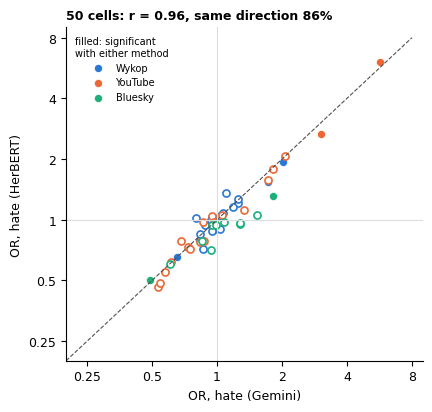

In [9]:
# ---------------------------------------------------------------- 4b. HerBERT vs Gemini (cells) -------------------
g_ = eff[eff.measure == "hate"].set_index("cell")
h_ = eff[eff.measure == "hate_herbert"].set_index("cell")
both = g_[["logOR", "OR", "sig", "platform"]].join(h_[["logOR", "OR", "sig"]], rsuffix="_hb", how="inner").dropna(subset=["logOR", "logOR_hb"])
sig_any = both["sig"] | both["sig_hb"]
R["herbert_vs_gemini"] = {
    "cells": len(both), "pearson_logOR": float(np.corrcoef(both["logOR"], both["logOR_hb"])[0, 1]),
    "spearman": float(stats.spearmanr(both["logOR"], both["logOR_hb"])[0]),
    "same_direction": float((np.sign(both["logOR"]) == np.sign(both["logOR_hb"])).mean()),
    "sig_gemini": int(both["sig"].sum()), "sig_herbert": int(both["sig_hb"].sum()), "sig_both": int((both["sig"] & both["sig_hb"]).sum()),
    "sig_any_same_direction": float((np.sign(both.loc[sig_any, "logOR"]) == np.sign(both.loc[sig_any, "logOR_hb"])).mean()) if sig_any.any() else None,
    "sig_herbert_cells": both.index[both["sig_hb"]].tolist(), "sig_gemini_cells": both.index[both["sig"]].tolist(),
}
print("HerBERT vs Gemini", R["herbert_vs_gemini"], flush=True)
jdump()
fig, ax = plt.subplots(figsize=(4.4, 4.2))
for p in PLATFORMS:
    b_ = both[both.platform == p]
    sg = b_["sig"] | b_["sig_hb"]
    ax.scatter(b_.loc[~sg, "OR"], b_.loc[~sg, "OR_hb"], s=26, facecolor="white", edgecolor=PCOL[p], lw=1.2)
    ax.scatter(b_.loc[sg, "OR"], b_.loc[sg, "OR_hb"], s=34, color=PCOL[p], edgecolor="white", lw=0.5, label=PNAME[p])
ax.plot([0.2, 8], [0.2, 8], ls="--", color=INK2, lw=0.8)
ax.axhline(1, color="#dddddd", lw=0.8); ax.axvline(1, color="#dddddd", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
for f_ in (ax.set_xticks, ax.set_yticks):
    f_([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
ax.minorticks_off(); ax.set_xlim(0.2, 9); ax.set_ylim(0.2, 9)
ax.set_xlabel("OR, hate (Gemini)"); ax.set_ylabel("OR, hate (HerBERT)")
hv = R["herbert_vs_gemini"]
ax.set_title(f"{hv['cells']} cells: r = {hv['pearson_logOR']:.2f}, same direction {100 * hv['same_direction']:.0f}%", fontsize=9)
ax.legend(fontsize=7, loc="upper left", title="filled: significant\nwith either method", title_fontsize=7)
plt.tight_layout()
save(fig, "fig_herbert_en")

## 5. Wykresy H1–H3 (do preprintu)

In [10]:
# ---------------------------------------------------------------- 5. figures: H1-H3 ---------------------------------
ORDER = list(EVENTS)
LBL = {ev: v[0] for ev, v in EVENTS.items()}


def fmt_or(v):
    return f"{v:.2f}" if v < 10 else f"{v:.1f}"


def fig_heatmap():
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 6.3), sharey=True)
    for ax, y, title in zip(axes, ["hate", "hate_migrant"], ["General hate (hate)", "Hate toward migrants (hate_migrant)"]):
        M = np.full((len(ORDER), 3), np.nan)
        for i, ev in enumerate(ORDER):
            for j, p in enumerate(PLATFORMS):
                r = eff[(eff.measure == y) & (eff.cell == f"{p}:{ev}")]
                if len(r) and pd.notna(r["OR"].iloc[0]):
                    M[i, j] = np.log2(r["OR"].iloc[0])
        lim = 2.0
        ax.imshow(np.clip(M, -lim, lim), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for i, ev in enumerate(ORDER):
            for j, p in enumerate(PLATFORMS):
                cell = f"{p}:{ev}"
                inf = info[(info.platform == p) & (info.event == ev)]
                r = eff[(eff.measure == y) & (eff.cell == cell)]
                if len(r) and pd.notna(r["OR"].iloc[0]):
                    v = r["OR"].iloc[0]
                    s = fmt_or(v) + ("*" if r["sig"].iloc[0] else "")
                    ax.text(j, i, s, ha="center", va="center", fontsize=7.6,
                            color="white" if abs(np.log2(v)) > 1.2 else INK,
                            fontweight="bold" if r["sig"].iloc[0] else "normal")
                elif len(inf):
                    ax.text(j, i, "·", ha="center", va="center", fontsize=11, color=MUTED)
        ax.set_xticks(range(3), [PNAME[p] for p in PLATFORMS])
        ax.set_yticks(range(len(ORDER)), [LBL[e] for e in ORDER])
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(title, fontsize=9.5)
    fig.text(0.5, 0.005, "OR after vs. before (red > 1 > blue);  * significant after Holm;  · fewer than 30 comments; empty: no data",
             ha="center", fontsize=7.5, color=INK2)
    plt.tight_layout(rect=(0, 0.02, 1, 1))
    save(fig, "fig_heatmap_en")


def fig_pooled():
    fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.0), sharey=True)
    for ax, y, title in zip(axes, ["hate", "hate_migrant", "migrant"],
                            ["hate", "hate_migrant", "migrant (share of comments about migration)"]):
        e = eff[(eff.measure == y)].dropna(subset=["OR"])
        jit = rng.uniform(-0.25, 0.25, len(e))
        ax.scatter(e["OR"], 2 + jit, c=[PCOL[p] for p in e.platform], s=16, alpha=0.8, edgecolor="white", lw=0.4)
        r = R["H1"][y]
        a = r["all"]
        ax.fill([a["lo"], a["OR"], a["hi"], a["OR"]], [1, 1.22, 1, 0.78], color=INK)
        if "pooled_model" in r:
            pm = r["pooled_model"]
            ax.hlines(0, pm["lo"], pm["hi"], color=INK2, lw=1.5)
            ax.scatter(pm["OR"], 0, marker="s", s=30, color=INK2, zorder=3)
        ax.axvline(1, ls="--", color=INK2, lw=0.9)
        ax.set_xscale("log")
        ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
        ax.minorticks_off()
        ax.set_xlim(0.15, 12)
        ax.set_title(title, fontsize=9)
        ax.text(0.02, 0.97, f"meta OR {a['OR']:.2f} [{a['lo']:.2f}, {a['hi']:.2f}]\np = {a['p']:.2f}, I² = {100 * a['I2']:.0f}%",
                transform=ax.transAxes, va="top", fontsize=7.5, color=INK)
    axes[0].set_yticks([0, 1, 2], ["comment-level\nmodel", "meta-analysis", "cells"])
    axes[0].set_ylim(-0.6, 3.3)
    h = [plt.Line2D([], [], marker="o", ls="", color=PCOL[p], label=PNAME[p]) for p in PLATFORMS]
    axes[2].legend(handles=h, loc="lower right", fontsize=7.5)
    fig.supxlabel("OR after vs. before (log scale)", fontsize=8.5)
    plt.tight_layout()
    save(fig, "fig_pooled_en")


def fig_decomp():
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 6.6), sharey=True)
    evs = [ev for ev in ORDER if ev in set(dec.event)]
    rows_ = evs + ["ALL"]
    cols = {"total": INK, "attention": "#0f766e", "tone": "#c2410c"}
    off = {"total": -0.22, "attention": 0, "tone": 0.22}
    for ax, lab, title in zip(axes, ["hate", "hate_migrant"], ["General hate", "Hate toward migrants"]):
        for i, ev in enumerate(rows_):
            for comp in cols:
                r = dec[(dec.event == ev) & (dec.label == lab) & (dec.component == comp)]
                if r.empty or r["OR"].isna().all():
                    continue
                r = r.iloc[0]
                sig = (r["p_holm"] < 0.05) if ev != "ALL" else (r["p"] < 0.05)
                y_ = i + off[comp]
                ax.hlines(y_, r["lo"], r["hi"], color=cols[comp], lw=1.2)
                ax.scatter(r["OR"], y_, s=26, color=cols[comp] if sig else "white", edgecolor=cols[comp], lw=1.3, zorder=3)
        ax.axvline(1, ls="--", color=INK2, lw=0.9)
        ax.axhline(len(evs) - 0.5, color="#dddddd", lw=0.8)
        ax.set_xscale("log")
        ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
        ax.minorticks_off()
        ax.set_xlim(0.12, 16)
        ax.set_title(title, fontsize=9.5)
        ax.set_xlabel("OR after vs. before (log scale)")
    axes[0].set_yticks(range(len(rows_)), [LBL.get(e, "All events") for e in rows_])
    axes[0].invert_yaxis()
    h = [plt.Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in
         [("hate (total)", INK), ("attention: comments about migration", "#0f766e"), ("tone: hate among comments about migration", "#c2410c")]]
    fig.legend(handles=h, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.6, -0.02))
    plt.tight_layout(rect=(0, 0.035, 1, 1))
    save(fig, "fig_decomp_en")


def fig_h2():
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True)
    for ax, y, title in zip(axes, ["hate", "hate_migrant"], ["hate", "hate_migrant"]):
        e = eff[(eff.measure == y)].dropna(subset=["OR"])
        for xi, t in enumerate(TYPES):
            g = e[e["type"] == t]
            if g.empty:
                continue
            ax.scatter(xi + rng.uniform(-0.17, 0.17, len(g)), g["OR"], c=[PCOL[p] for p in g.platform], s=18,
                       edgecolor="white", lw=0.4, zorder=3)
            bt = R["H2"][y]["by_type"][t]
            if bt.get("OR") is not None:
                ax.vlines(xi + 0.32, bt["lo"], bt["hi"], color=TCOL[t], lw=1.6)
                ax.scatter(xi + 0.32, bt["OR"], marker="D", s=40, color=TCOL[t], zorder=4)
        ax.axhline(1, ls="--", color=INK2, lw=0.9)
        ax.set_yscale("log")
        ax.set_yticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
        ax.set_ylim(0.15, 9)
        ax.minorticks_off()
        ax.set_xticks(range(len(TYPES)), [t.replace(" ", "\n") for t in TYPES], fontsize=8)
        ax.set_title(f"{title}: F = {R['H2'][y]['F']:.2f}, permutation p = {R['H2'][y]['p_perm']:.2f}", fontsize=9)
    axes[0].set_ylabel("OR after vs. before (log scale)")
    h = [plt.Line2D([], [], marker="o", ls="", color=PCOL[p], label=PNAME[p]) for p in PLATFORMS]
    axes[1].legend(handles=h, loc="upper right", fontsize=7)
    plt.tight_layout()
    save(fig, "fig_h2_en")


def fig_h3():
    fig, axes = plt.subplots(2, 2, figsize=(10.2, 6.6), gridspec_kw={"width_ratios": [1, 2.4]})
    for row, y in enumerate(["hate", "hate_migrant"]):
        ax = axes[row, 0]
        h3 = R["H3"][y]
        for k, p in enumerate(PLATFORMS):
            r = h3["by_platform"][p]
            if r.get("OR") is None:
                continue
            ax.plot([0, 1], [1, r["OR"]], color=PCOL[p], lw=2)
            ax.errorbar(1 + 0.04 * (k - 1), r["OR"], yerr=[[r["OR"] - r["lo"]], [r["hi"] - r["OR"]]], color=PCOL[p],
                        capsize=3, marker="o", ms=5)
        ys = sorted([(h3["by_platform"][p]["OR"], p) for p in PLATFORMS if h3["by_platform"][p].get("OR")])
    lab_y, prev = {}, None
    for v, p in ys:
        yv = v if prev is None else max(v, prev * 1.07)
        lab_y[p] = prev = yv
    for p in lab_y:
        ax.text(1.12, lab_y[p], f"{PNAME[p]} {h3['by_platform'][p]['OR']:.2f}", va="center", fontsize=7.5, color=PCOL[p])
        ax.set_xticks([0, 1], ["before", "after"])
        ax.set_xlim(-0.15, 1.75)
        ax.set_yscale("log")
        ax.set_yticks([0.5, 0.75, 1, 1.5, 2], ["0.5", "0.75", "1", "1.5", "2"])
        ax.minorticks_off()
        ax.axhline(1, ls=":", color=INK2, lw=0.8)
        ax.set_title(f"{y}: Q = {h3['Q']:.2f}, p = {h3['p_Q']:.2f}", fontsize=9)
        ax.set_ylabel("average OR")
        ax = axes[row, 1]
        e = eff[(eff.measure == y)].dropna(subset=["OR"])
        evs = [ev for ev in ORDER if e[e.event == ev]["platform"].nunique() >= 2]
        for k, p in enumerate(PLATFORMS):
            g = e[e.platform == p].set_index("event").reindex(evs)
            x = np.arange(len(evs)) + (k - 1) * 0.22
            ok = g["OR"].notna().values
            ax.vlines(x[ok], g["lo"][ok], g["hi"][ok], color=PCOL[p], lw=1.1)
            ax.scatter(x[ok], g["OR"][ok], color=PCOL[p], s=16, zorder=3, label=PNAME[p])
        ax.axhline(1, ls="--", color=INK2, lw=0.8)
        ax.set_yscale("log")
        ax.set_yticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
        ax.minorticks_off()
        ax.set_ylim(0.12, 16)
        ax.set_xticks(range(len(evs)), [LBL[e_] for e_ in evs], rotation=40, ha="right", fontsize=7.2)
        ax.set_title(f"{y}: events observed on at least two platforms", fontsize=9)
        if row == 0:
            ax.legend(fontsize=7, ncol=3, loc="upper right")
    plt.tight_layout()
    save(fig, "fig_h3_en")


def fig_daily(events_sel):
    days = np.arange(WINDOW[0], WINDOW[1] + 1)
    fig, axes = plt.subplots(len(events_sel), 2, figsize=(8.6, 1.9 * len(events_sel) + 0.4), sharex=True, squeeze=False)
    for i, ev in enumerate(events_sel):
        for j, y in enumerate(["hate_migrant", "migrant"]):
            ax = axes[i, j]
            ax2 = ax.twinx()
            for p in PLATFORMS:
                d = A[(A.event == ev) & (A.platform == p)]
                if d.empty:
                    continue
                t = d.groupby("relative_day")[y].agg(["mean", "size"]).reindex(days)
                base = d.loc[d.po == 0, y].mean()
                if not base or np.isnan(base):
                    continue
                idx = (t["mean"] / base).rolling(3, center=True, min_periods=1).mean()
                ax.plot(days, idx, color=PCOL[p], lw=1.6, label=PNAME[p])
                ax2.bar(days + {"wykop": -0.27, "youtube": 0, "bluesky": 0.27}[p], t["size"].fillna(0), 0.26,
                        color=PCOL[p], alpha=0.16)
            ax2.set_yticks([]); ax2.spines["right"].set_visible(False)
            ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
            ax.axvline(0, ls="--", color=INK, lw=0.8)
            ax.axhline(1, ls=":", color=INK2, lw=0.8)
            if i == 0:
                ax.set_title("hate toward migrants (index)" if j == 0 else "comments about migration (index)", fontsize=9)
            if j == 0:
                ax.set_ylabel(LBL[ev], fontsize=8)
        if i == 0:
            fig.legend(handles=[plt.Line2D([], [], color=PCOL[p], lw=2, label=PNAME[p]) for p in PLATFORMS], loc="upper center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, 1.02))
    for ax in axes[-1]:
        ax.set_xlabel("day relative to the event")
    plt.tight_layout(rect=(0, 0, 1, 0.965))
    save(fig, "fig_daily_en")

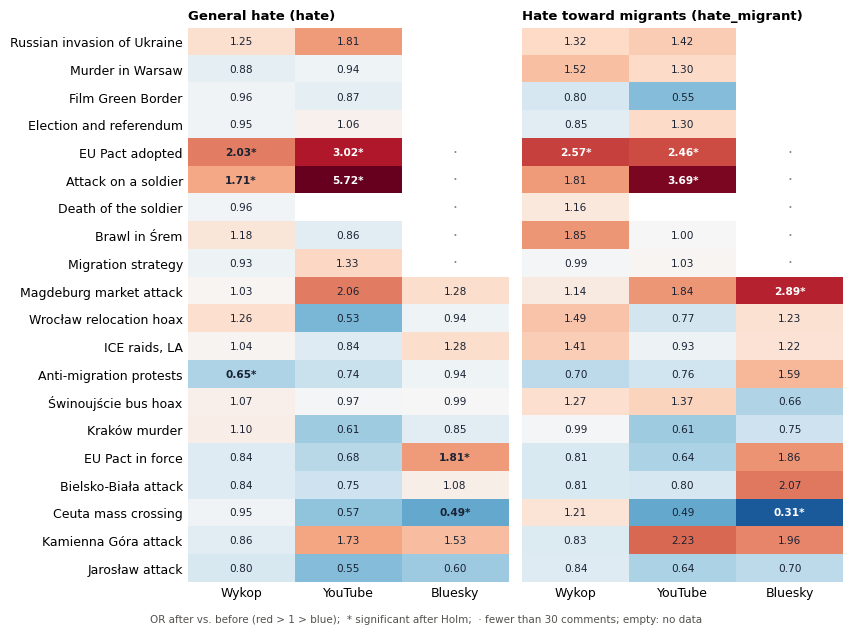

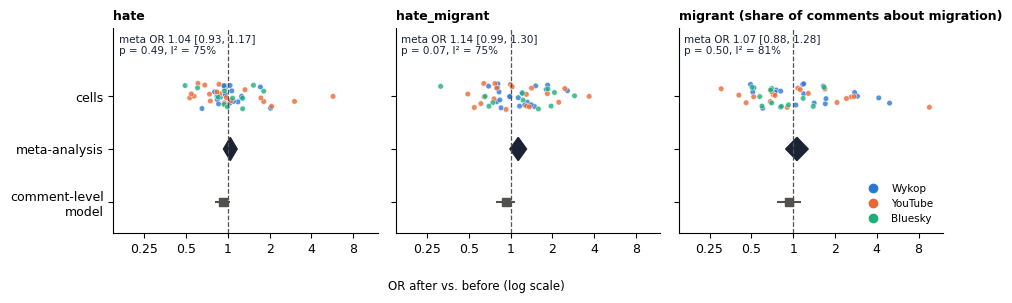

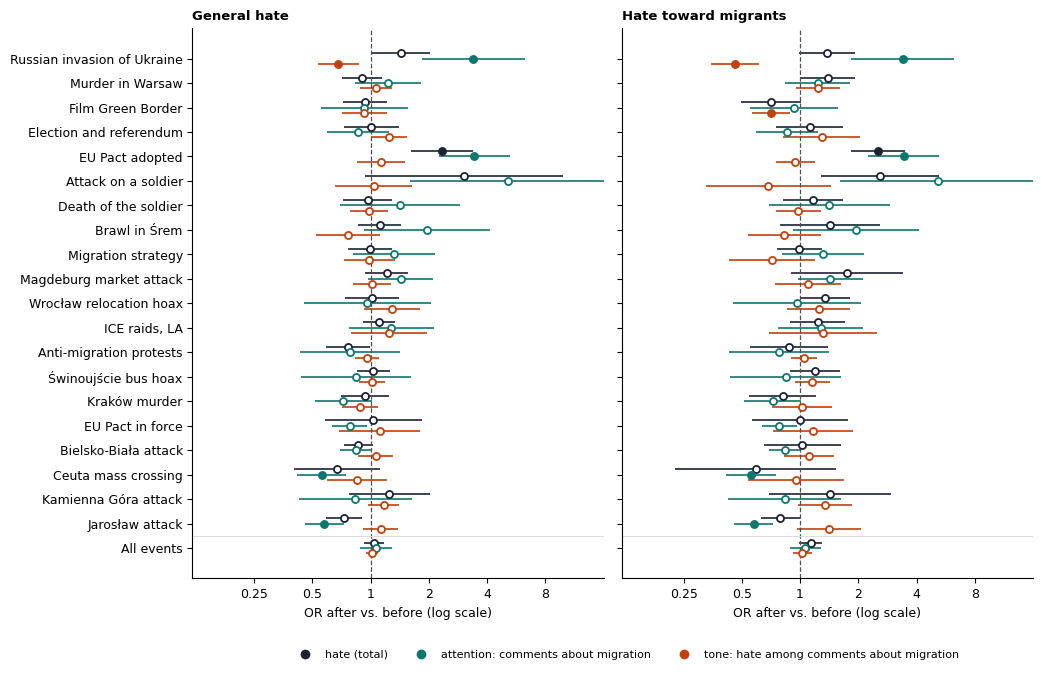

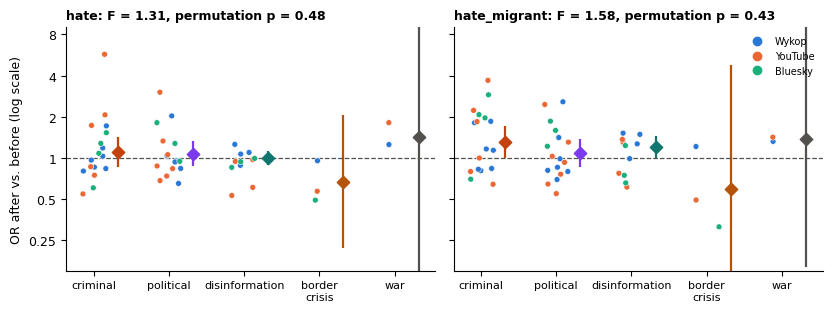

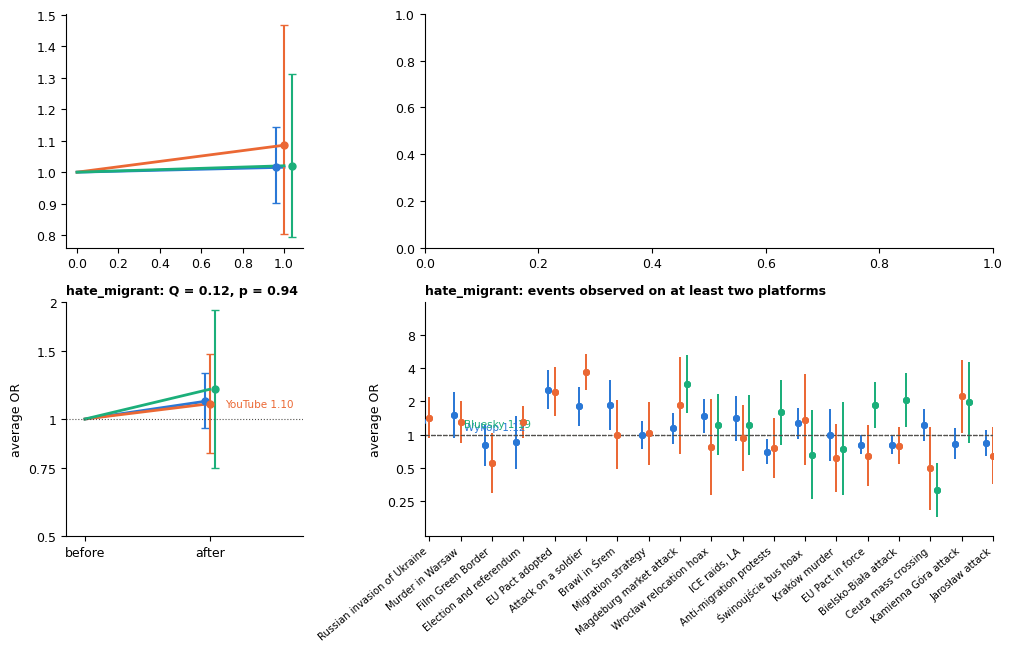

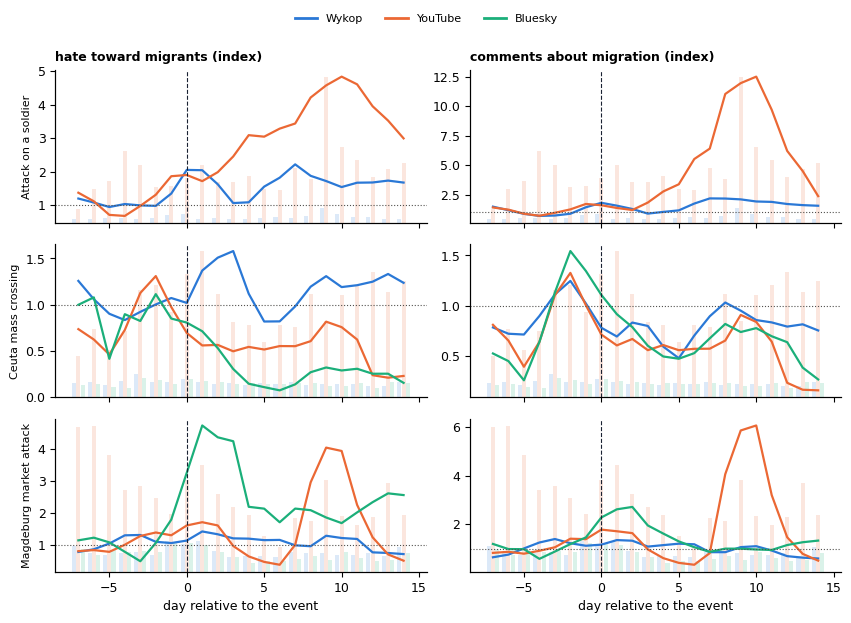

H figures done


In [11]:
fig_heatmap(); fig_pooled(); fig_decomp(); fig_h2(); fig_h3()
# events for the timing figure: the events with the largest significant changes in hate_migrant
s = eff[(eff.measure == "hate_migrant") & eff.sig].copy()
s["abs"] = np.abs(np.log(s["OR"]))
sel = list(dict.fromkeys(s.sort_values("abs", ascending=False)["event"]))[:3]
R["daily_events"] = sel
if sel:
    fig_daily(sel)
# daily peak per selected event and platform (for the text)
peaks = {}
for ev in sel:
    for p in PLATFORMS:
        d = A[(A.event == ev) & (A.platform == p)]
        if d.empty:
            continue
        t = d.groupby("relative_day")["hate_migrant"].mean()
        base = d.loc[d.po == 0, "hate_migrant"].mean()
        if base and not np.isnan(base):
            idx = (t / base).rolling(3, center=True, min_periods=1).mean()
            post = idx[idx.index >= 0]
            peaks[f"{p}:{ev}"] = {"peak_day": int(post.idxmax()), "peak_index": float(post.max()),
                                  "last_days_index": float(idx[idx.index >= 10].mean())}
R["daily_peaks"] = peaks
jdump()
print("H figures done", flush=True)

## 6. Q1(a) – hejt wobec migrantów: słowa, cele, autorzy, lajki
Komentarze `hate_migrant` porównujemy z pozostałymi komentarzami o migracji (`migrant` = 1).

In [12]:
# ---------------------------------------------------------------- 6. Q1(a) hate toward migrants -----------------------
STOP = set("""a aby ach acz ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym być był była było były będzie będą cali cała cały
chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze dokąd dość
dużo dwa dziś dzisiaj gdy gdyby gdyż gdzie go i ich ile im inna inne inny innych iż ja ją jak jakaś jakby jaki jakie jakiś jako je jeden
jedna jedno jednak jego jej jemu jest jestem jeszcze jeśli jeżeli już każdy kiedy kilka kto ktoś która które którego której który
których którym którzy lecz lub ma mają mam mamy mało mi mimo między mną mnie mogą moja moje może można mój mu musi my na nad nam nami
nas nasi nasz nasza nasze naszego naszych nawet nic nich nie niech niego niej nigdy nim nimi niż no o od on ona one oni ono oraz oto
po pod podczas ponad ponieważ powinien powinni poza prawie przecież przed przez przy również sam sama są się sobie sobą swoje ta tak
taka taki takie także tam te tego tej temu ten teraz też to tobą tobie trzeba tu tutaj twoja twoje twój ty tych tylko tym u w wam was
wasz we według wiele wielu więc więcej wszyscy wszystkich wszystkie wszystko wtedy wy właśnie z za zawsze ze znowu znów żaden że żeby
tez juz sie ktory ktora ktore bylo byl beda bedzie moze takze zeby niz jakis jakies cos nikt mieć móc chcieć wiedzieć mówić czas rok
raz który swój wszystek inny jakiś cały http https www com xd xdd link user""".split())
TOK = re.compile(r"[a-ząćęłńóśźż]{3,}")


def build_tok():
    import simplemma
    cache = {}

    def lem(t):
        if t not in cache:
            cache[t] = simplemma.lemmatize(t, lang="pl").lower()
        return cache[t]
    stop = STOP | {lem(w) for w in STOP}

    def toks(text):
        return [w for w in (lem(t) for t in TOK.findall(str(text).lower())) if w not in stop and len(w) >= 3]
    return toks


def log_odds(c1, c2, prior, min_count=10):
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["word", "n_hate", "n_other", "z"]).sort_values("z", ascending=False)


TARGETS = {
    "Ukrainians": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|chachoł|chochoł|upadlin",
    "Muslims / Arabs": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|szariat|meczet",
    "Africans": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "migrants in general": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}


def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    return x[:max(1, int(np.ceil(q * len(x))))].sum() / x.sum()

In [13]:
# texts of the comments in the analysis window that passed the topic filter (row index = df index)
T = A.loc[A["topic"], ["cell", "platform", "event", "po", "migrant", "hate", "hate_migrant", "slur", "author",
                       "likes", "replies", "thread", "hate_herbert"]]
del A
gc.collect()
TX = TX.loc[T.index]
T["text"] = TX["text"].fillna("").astype(str)
if "text_raw" in TX and ("q1b" in STEPS or not STEPS):
    raw = TX["text_raw"]
    T["text_raw"] = raw.where(raw.notna() & (raw != ""), T["text"])
    del raw
else:
    T["text_raw"] = T["text"]
del TX
gc.collect()
toks = build_tok()

In [14]:
HM = T[T["hate_migrant"]]
NH = T[T["migrant"] & ~T["hate_migrant"]]
R["q1a"] = {"n_hate_migrant": len(HM), "by_platform": HM.groupby("platform", observed=True).size().to_dict()}
terms = {}
for p in PLATFORMS:
    terms[(p, 1)] = Counter(w for t in HM.loc[HM.platform == p, "text"] for w in toks(t))
    terms[(p, 0)] = Counter(w for t in NH.loc[NH.platform == p, "text"] for w in toks(t))
uh = sum((terms[(p, 1)] for p in PLATFORMS), Counter())
un = sum((terms[(p, 0)] for p in PLATFORMS), Counter())
R["q1a"]["top_words"] = uh.most_common(40)

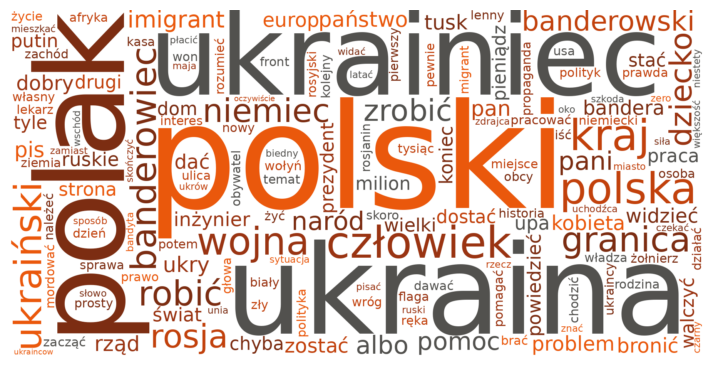

7177

In [15]:
# cloud
from wordcloud import WordCloud
from matplotlib import font_manager
shades = ["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#52514e"]
wc = WordCloud(width=1800, height=900, background_color="white", max_words=150, prefer_horizontal=0.95,
               font_path=font_manager.findfont("DejaVu Sans"), random_state=0, margin=4,
               color_func=lambda *a, random_state=None, **k: random_state.choice(shades)
               ).generate_from_frequencies(dict(uh.most_common(400)))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
save(fig, "fig_cloud_en")
wc.to_file(str(OUT / "cloud_src.png"))
# word counts only (lemmas, no comment texts) for the figure script
(OUT / "cloud_freq.json").write_text(json.dumps(uh.most_common(400), ensure_ascii=False), encoding="utf-8")

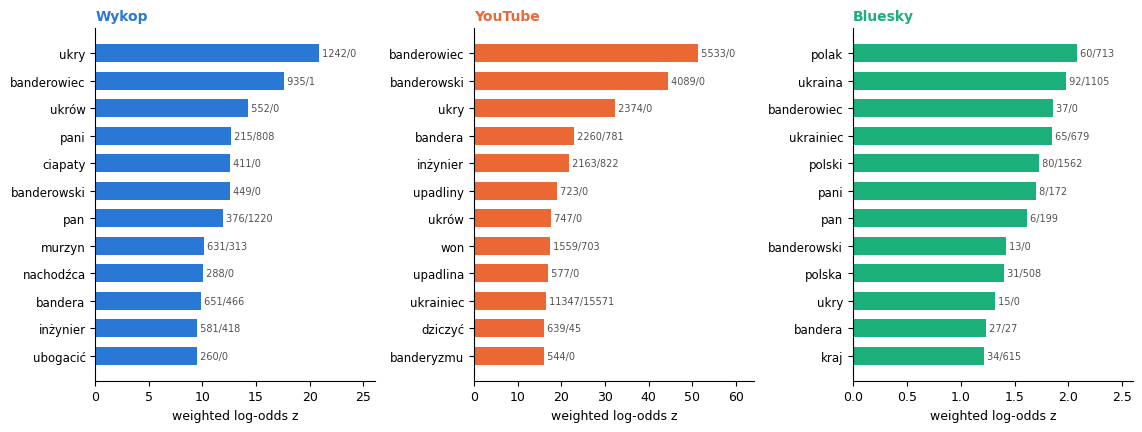

In [16]:
# distinctive words per platform
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.4))
R["q1a"]["distinctive"] = {}
for ax, p in zip(axes, PLATFORMS):
    lo_ = log_odds(terms[(p, 1)], terms[(p, 0)], uh + un, min_count=5).head(15)
    R["q1a"]["distinctive"][p] = lo_[["word", "n_hate", "n_other", "z"]].values.tolist()
    lo_ = lo_.head(12)
    y_ = np.arange(len(lo_))[::-1]
    ax.barh(y_, lo_["z"], color=PCOL[p], height=0.65)
    for yi, (z, a, b) in zip(y_, lo_[["z", "n_hate", "n_other"]].values):
        ax.text(z, yi, f" {int(a)}/{int(b)}", va="center", fontsize=7, color=INK2)
    ax.set_yticks(y_, lo_["word"], fontsize=8.5)
    ax.margins(x=0.25)
    ax.set_title(PNAME[p], color=PCOL[p])
    ax.set_xlabel("weighted log-odds z")
plt.tight_layout()
save(fig, "fig_words_en")

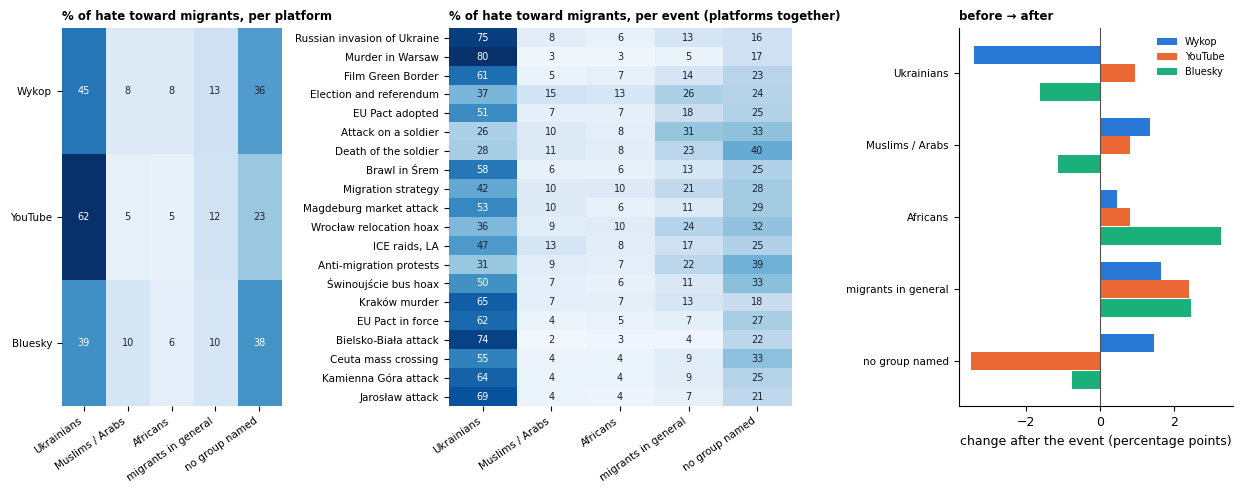

In [17]:
# targets
low = HM["text"].str.lower()
tg = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGETS.items()}, index=HM.index)
tg["no group named"] = ~tg.any(axis=1)
cols_tg = list(tg.columns)
tg[["platform", "event", "po"]] = HM[["platform", "event", "po"]].astype(str).values
by_pl = 100 * tg.groupby("platform")[cols_tg].mean().reindex(PLATFORMS)
ev_ok = [ev for ev in ORDER if (tg.event == ev).sum() >= 30]
by_ev = 100 * tg[tg.event.isin(ev_ok)].groupby("event")[cols_tg].mean().reindex(ev_ok)
chg = 100 * tg.groupby(["platform", "po"])[cols_tg].mean()
R["q1a"]["targets_by_platform"] = by_pl.round(1).to_dict("index")
R["q1a"]["targets_by_event"] = by_ev.round(1).to_dict("index")
R["q1a"]["targets_n"] = {"platform": tg.groupby("platform").size().to_dict(),
                         "event": tg[tg.event.isin(ev_ok)].groupby("event").size().to_dict()}
R["q1a"]["targets_change_pp"] = {p: (chg.loc[(p, "1")] - chg.loc[(p, "0")]).round(1).to_dict()
                                 for p in PLATFORMS if (p, "0") in chg.index and (p, "1") in chg.index}
fig, axes = plt.subplots(1, 3, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [0.8, 1.25, 1]})
for ax, tab, title in [(axes[0], by_pl.rename(index=PNAME), "per platform"),
                       (axes[1], by_ev.rename(index=LBL), "per event (platforms together)")]:
    vmax = np.nanmax(tab.values)
    ax.imshow(tab.values, cmap="Blues", aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 * vmax else INK)
    ax.set_xticks(range(len(cols_tg)), cols_tg, rotation=35, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(tab)), tab.index, fontsize=7.5)
    ax.set_title(f"% of hate toward migrants, {title}", fontsize=8.5)
    for s in ax.spines.values():
        s.set_visible(False)
ax = axes[2]
yy = np.arange(len(cols_tg))
for k, p in enumerate(PLATFORMS):
    if (p, "0") in chg.index and (p, "1") in chg.index:
        ax.barh(yy + (k - 1) * 0.26, (chg.loc[(p, "1")] - chg.loc[(p, "0")]).values, 0.25, color=PCOL[p], label=PNAME[p])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(yy, cols_tg, fontsize=7.5); ax.invert_yaxis()
ax.set_xlabel("change after the event (percentage points)"); ax.legend(fontsize=7)
ax.set_title("before → after", fontsize=8.5)
plt.tight_layout()
save(fig, "fig_targets_en")

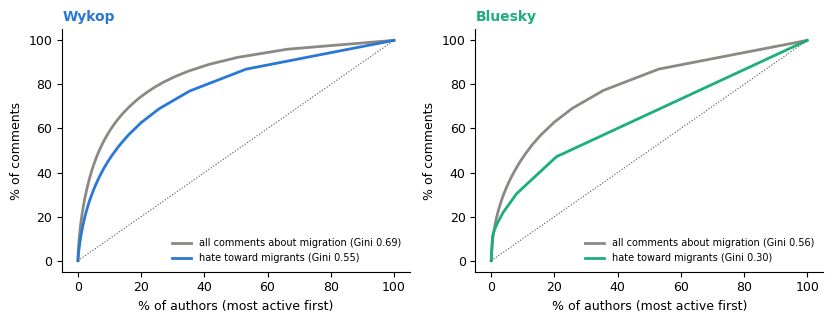

In [18]:
# authors (Wykop, Bluesky)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.3))
R["q1a"]["authors"] = {}
R["q1a"]["lorenz"] = {}
for ax, p in zip(axes, ["wykop", "bluesky"]):
    d = T[(T.platform == p) & T["migrant"] & T["author"].notna()]
    pa = d.groupby("author", observed=True).agg(all=("migrant", "size"), hate=("hate_migrant", "sum"))
    pa = pa[pa["all"] > 0]
    hat = pa.loc[pa["hate"] > 0, "hate"]
    for x_, col, nm in [(pa["all"], MUTED, "all comments about migration"), (hat, PCOL[p], "hate toward migrants")]:
        xs = np.sort(x_.values)[::-1]
        lx = np.r_[0, np.arange(1, len(xs) + 1) / len(xs)]
        ly = np.r_[0, np.cumsum(xs) / xs.sum()]
        ax.plot(100 * lx, 100 * ly, color=col, lw=2, label=f"{nm} (Gini {gini(x_):.2f})")
        pick = np.unique(np.r_[np.linspace(0, len(lx) - 1, 300).astype(int), np.arange(min(len(lx), 60))])
        R["q1a"]["lorenz"].setdefault(p, {})["all" if col == MUTED else "hate"] = [lx[pick].round(5).tolist(),
                                                                                  ly[pick].round(5).tolist()]
    ax.plot([0, 100], [0, 100], ls=":", color=INK2, lw=0.8)
    ax.set_xlabel("% of authors (most active first)"); ax.set_ylabel("% of comments")
    ax.set_title(PNAME[p], color=PCOL[p]); ax.legend(fontsize=7, loc="lower right")
    R["q1a"]["authors"][p] = {"authors": len(pa), "gini_all": gini(pa["all"]), "gini_hate": gini(hat),
                              "top20_all": top_share(pa["all"], .2), "top20_hate": top_share(hat, .2),
                              "share_authors_with_hate": len(hat) / len(pa)}
plt.tight_layout()
save(fig, "fig_authors_en")

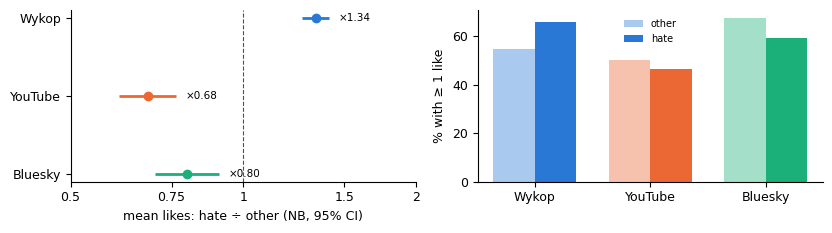

Q1a done


In [19]:
# likes (comments about migration: hate toward migrants vs other)
like_rows = []
for p in PLATFORMS:
    d = T[(T.platform == p) & T["migrant"]].dropna(subset=["likes"]).copy()
    if len(d) < 300:
        continue
    d["likes"] = d["likes"].clip(lower=0)
    d["h"] = d["hate_migrant"].astype(float)
    X = pd.get_dummies(d["cell"].astype(str), drop_first=True, dtype=float)
    X.insert(0, "h", d["h"].values)
    X = sm.add_constant(X)
    try:
        f = sm.GLM(d["likes"].values, X, family=sm.families.NegativeBinomial(alpha=1.0)).fit(
            cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        b, se, pv = f.params["h"], f.bse["h"], f.pvalues["h"]
    except Exception as ex:
        print("NB failed", p, ex); b = se = pv = np.nan
    like_rows.append({"platform": p, "ratio": np.exp(b), "lo": np.exp(b - 1.96 * se), "hi": np.exp(b + 1.96 * se),
                      "p": pv, "pct1_hate": (d.loc[d.h == 1, "likes"] >= 1).mean(),
                      "pct1_other": (d.loc[d.h == 0, "likes"] >= 1).mean()})
likes = pd.DataFrame(like_rows).set_index("platform")
R["q1a"]["likes"] = likes.to_dict("index")
fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.4))
ax = axes[0]; yy = np.arange(len(likes))
for yi, (p, r) in zip(yy, likes.iterrows()):
    ax.hlines(yi, r["lo"], r["hi"], color=PCOL[p], lw=2)
    ax.scatter(r["ratio"], yi, color=PCOL[p], s=36, zorder=3)
    ax.text(r["hi"] * 1.04, yi, f"×{r['ratio']:.2f}", va="center", fontsize=7.5)
ax.axvline(1, ls="--", color=INK2, lw=0.8); ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2], ["0.5", "0.75", "1", "1.5", "2"]); ax.minorticks_off()
ax.set_yticks(yy, [PNAME[p] for p in likes.index]); ax.invert_yaxis()
ax.set_xlabel("mean likes: hate ÷ other (NB, 95% CI)")
ax = axes[1]; w = 0.36
ax.bar(yy - w / 2, 100 * likes["pct1_other"], w, color=[PCOL[p] for p in likes.index], alpha=0.4, label="other")
ax.bar(yy + w / 2, 100 * likes["pct1_hate"], w, color=[PCOL[p] for p in likes.index], label="hate")
ax.set_xticks(yy, [PNAME[p] for p in likes.index]); ax.set_ylabel("% with ≥ 1 like"); ax.legend(fontsize=7)
plt.tight_layout()
save(fig, "fig_likes_en")
jdump()
print("Q1a done", flush=True)

## Najważniejsze liczby
Wszystko jest też w `reports/final_gemini/results.json`.

In [20]:
for y in ["hate", "hate_migrant", "migrant", "hate_herbert"]:
    a = R["H1"][y]["all"]
    print(f"H1 {y:13s} OR {a['OR']:.2f} [{a['lo']:.2f}, {a['hi']:.2f}], p = {a['p']:.3f}, I2 = {100 * a['I2']:.0f}%")
for y in ["hate", "hate_migrant", "hate_herbert"]:
    print(f"H2 {y:13s} F = {R['H2'][y]['F']:.2f}, p_perm = {R['H2'][y]['p_perm']:.2f}")
    print(f"H3 {y:13s} Q = {R['H3'][y]['Q']:.2f}, p = {R['H3'][y]['p_Q']:.2f}; panel p = {R['H3'][y]['p_Q_panel']:.2f}")
print("HerBERT vs Gemini:", {k: v for k, v in R["herbert_vs_gemini"].items() if not isinstance(v, list)})

H1 hate          OR 1.04 [0.93, 1.17], p = 0.486, I2 = 75%
H1 hate_migrant  OR 1.14 [0.99, 1.30], p = 0.070, I2 = 75%
H1 migrant       OR 1.07 [0.88, 1.28], p = 0.501, I2 = 81%
H1 hate_herbert  OR 0.99 [0.89, 1.10], p = 0.782, I2 = 70%
H2 hate          F = 1.31, p_perm = 0.48
H3 hate          Q = 0.20, p = 0.90; panel p = 0.40
H2 hate_migrant  F = 1.58, p_perm = 0.43
H3 hate_migrant  Q = 0.12, p = 0.94; panel p = 0.34
H2 hate_herbert  F = 1.22, p_perm = 0.40
H3 hate_herbert  Q = 3.15, p = 0.21; panel p = 0.46
HerBERT vs Gemini: {'cells': 50, 'pearson_logOR': 0.9620577391360677, 'spearman': 0.9032893157262905, 'same_direction': 0.86, 'sig_gemini': 7, 'sig_herbert': 4, 'sig_both': 4, 'sig_any_same_direction': 1.0}


## Liczby cytowane w preprincie (H1–H3)
Każda liczba z wyników H1–H3 w preprincie, w kolejności tekstu.

In [21]:
cdf = pd.read_csv(OUT / "cell_effects.csv")
for y in ["hate", "hate_migrant", "hate_herbert"]:
    g = cdf[cdf.measure == y]
    print(f"{y:13s} significant cells (Holm): {int(g.sig.sum())} of {g.OR.notna().sum()}:",
          [(c, round(o, 2)) for c, o in zip(g[g.sig].cell, g[g.sig].OR)])
print()
for y in ["hate", "hate_migrant", "hate_herbert"]:
    a = R["H1"][y]["all"]
    print(f"H1 {y:13s} all cells OR {a['OR']:.2f} [{a['lo']:.2f}, {a['hi']:.2f}], p = {a['p']:.3f}, I2 = {100 * a['I2']:.0f}%")
    w = R["H1_wy"][y]
    print(f"   without Bluesky (k = {w['k']}): OR {w['OR']:.2f} [{w['lo']:.2f}, {w['hi']:.2f}], p = {w['p']:.3f}")
print()
for y in ["hate", "hate_migrant", "hate_herbert"]:
    h = R["H2"][y]
    print(f"H2 {y:13s} all cells: F = {h['F']:.2f}, p_F = {h['p_F']:.2f}, p_perm = {h['p_perm']:.2f}")
    if y in R["H2_wy"]:
        w = R["H2_wy"][y]
        print(f"   without Bluesky: F = {w['F']:.2f}, p_F = {w['p_F']:.2f}, p_perm = {w['p_perm']:.2f}")
    if "by_type" in h:
        print("   by type:", {t: (round(v['OR'], 2), round(v['lo'], 2), round(v['hi'], 2)) for t, v in h["by_type"].items()})
print()
for y in ["hate", "hate_migrant", "hate_herbert"]:
    w = R["H3_wy"][y]; r = w["ratio_W_over_Y"]
    print(f"H3 {y:13s} Wykop vs YouTube ({w['events']} events): ratio {r['OR']:.2f} [{r['lo']:.2f}, {r['hi']:.2f}], p = {r['p']:.2f};"
          f" Wald p = {w['p_wald']:.2f}; by platform", {p: round(v['OR'], 2) for p, v in w['by_platform'].items()})
    h = R["H3"][y]
    print(f"   3 platforms: (a) all cells Q = {h['Q']:.2f}, p = {h['p_Q']:.2f}; (b) 11 shared events Q = {h['Q_panel']:.2f},"
          f" p = {h['p_Q_panel']:.2f}; averages", {p: round(v['OR'], 2) for p, v in h['by_platform'].items()})
print()
d = pd.read_csv(OUT / "decomposition.csv")
print("decomposition (pooled over platforms): total / attention / tone")
for ev in ["2024-04-10_Pakt_Azyl_PE", "2022-02-24_Atak_Rosji_Ukraina", "2026-07-30_Ceuta_Masowe_Przekroczenie"]:
    for y in ["hate", "hate_migrant"]:
        s = d[(d.event == ev) & (d.label == y)].set_index("component")["OR"].round(2).to_dict()
        print(f"  {ev:40s} {y:13s}", s)
print("HerBERT vs Gemini:", {k: v for k, v in R["herbert_vs_gemini"].items() if not isinstance(v, list)})


hate          significant cells (Holm): 7 of 50: [('wykop:2024-04-10_Pakt_Azyl_PE', 2.03), ('wykop:2024-05-28_Atak_Zolnierz_Granica', 1.71), ('wykop:2025-07-19_Protesty_Antyimigracyjne_Polska', 0.65), ('youtube:2024-04-10_Pakt_Azyl_PE', 3.02), ('youtube:2024-05-28_Atak_Zolnierz_Granica', 5.72), ('bluesky:2026-06-12_Pakt_Migracyjny_Wejscie_w_Zycie', 1.81), ('bluesky:2026-07-30_Ceuta_Masowe_Przekroczenie', 0.49)]
hate_migrant  significant cells (Holm): 5 of 50: [('wykop:2024-04-10_Pakt_Azyl_PE', 2.57), ('youtube:2024-04-10_Pakt_Azyl_PE', 2.46), ('youtube:2024-05-28_Atak_Zolnierz_Granica', 3.69), ('bluesky:2024-12-20_Atak_Jarmark_Magdeburg', 2.89), ('bluesky:2026-07-30_Ceuta_Masowe_Przekroczenie', 0.31)]
hate_herbert  significant cells (Holm): 4 of 50: [('wykop:2024-04-10_Pakt_Azyl_PE', 1.94), ('youtube:2024-04-10_Pakt_Azyl_PE', 2.67), ('youtube:2024-05-28_Atak_Zolnierz_Granica', 6.03), ('bluesky:2026-07-30_Ceuta_Masowe_Przekroczenie', 0.5)]

H1 hate          all cells OR 1.04 [0.93, 1.17